# Fine-tune the final signal and noise masks

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src/data.py").exists():
    raise RuntimeError("Launch Jupyter from the repository or notebooks folder.")
sys.path.insert(0, str(root))
from src.data import ROOT, LEVELS, load, mix

Refit the output layer on training events, choosing the checkpoint with the lowest validation loss. The notebook writes a separate run folder and leaves the delivered weights available for comparison.

In [2]:
from src.train import train

out = ROOT / "runs/notebook_fit"
train(ROOT / "data/prepared", out)
loss = pd.read_csv(out / "loss.csv")
display(loss.loc[loss.validation_loss.idxmin()])

Selected epoch 40; validation cross-entropy 1.34127


epoch              40.000000
training_loss       1.417526
validation_loss     1.341268
Name: 40, dtype: float64

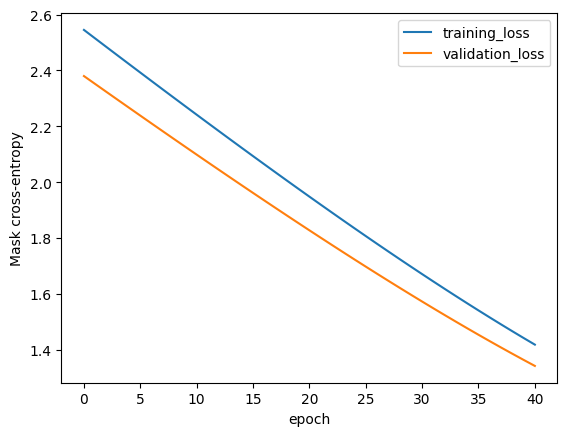

In [3]:
import matplotlib.pyplot as plt

loss.plot(
    x="epoch", y=["training_loss", "validation_loss"], ylabel="Mask cross-entropy"
)
plt.show()